# European Weightlifting: Competition Results and Medal Patterns

## Analytical focus

**How do medal outcomes and lifting results vary across countries, genders, and weight categories in the available European Championship data?**

This project combines supplied results with web-scraped championship tables. It preserves two stages: an initial analysis of the local files, followed by an extension of the dataset and the same analytical comparisons.

The notebook covers data reshaping, extraction of athlete and lift fields, quality checks, distributions, medal tables, and country comparisons.

## Reading guide

1. Supplied data sources
2. Preparing the supplied results
3. Performance patterns in the supplied results
4. Country comparisons in the supplied results
5. Extending the sources with web scraping
6. Preparing the combined results
7. Performance patterns in the combined results
8. Country comparisons in the combined results
9. Conclusions and limitations

**Source check:** the supplied file labelled 2020 contains the postponed 2021 edition. Its analytical year is corrected in memory. The combined dataset includes that edition once, retaining the supplied version of its results. Three medal records differ from the current source page; see the source-version note below.

## Case context and scope

The original case concerns Lift & Lead, a proposed specialist weightlifting-centre business seeking context about the sport and its athletes. The available championship results describe competitive performance and medal outcomes. They do not directly measure public interest in weightlifting, CrossFit participation, or demand for training centres.

The first stage uses two supplied CSV files labelled 2019 and 2020. The second file contains the championship held in 2021 after postponement. The analytical year is corrected to 2021 without editing the CSV. The second stage retrieves 2021–2024 tables and adds only the editions not already represented: 2022, 2023, and 2024.

**Source-version note:** 57 of the 60 supplied 2021 medal records match the current page after removing footnotes and normalizing whitespace. The three women’s 59 kg medal records differ. The supplied version is retained consistently in both stages; these are historical source records, not a claim of the latest revised medal allocation. The source page is not used to overwrite those three original records. [Source checks](docs/source_validation.md).

## 1. Supplied data sources

### Analysis environment

In [1]:
import pandas as pd 
import numpy as np 

import os
import re

import matplotlib.pyplot as plt
import seaborn as sns

import missingno as msno

import weightlifting_helpers as fpf
# English plot labels; source values and field names remain unchanged.
country_labels = {'Rusia': 'Russia', 'Armenia': 'Armenia', 'Bulgaria': 'Bulgaria', 'Georgia': 'Georgia', 'Rumania': 'Romania', 'Turquía': 'Turkey', 'Bielorrusia': 'Belarus', 'Ucrania': 'Ukraine', 'Italia': 'Italy', 'Reino Unido': 'United Kingdom', 'Francia': 'France', 'Letonia': 'Latvia', 'Alemania': 'Germany', 'Moldavia': 'Moldova', 'Bélgica': 'Belgium', 'Azerbaiyán': 'Azerbaijan', 'Albania': 'Albania', 'España': 'Spain', 'Polonia': 'Poland', 'Suecia': 'Sweden', 'Austria': 'Austria', 'Noruega': 'Norway', 'Irlanda': 'Ireland', 'Serbia': 'Serbia', 'Israel': 'Israel', 'Finlandia': 'Finland', 'AIN': 'Individual Neutral Athletes'}


### Load the local source files

In [2]:
folder = r'data/raw data'
file_list = [f for f in os.listdir(folder) if f.endswith('.csv')]
file_list

['Campeonato Europeo de Halterofilia de 2020 datos original.csv',
 'Campeonato Europeo de Halterofilia de 2019 datos original.csv']

In [3]:
df_dict = {}
for file in file_list:
    file_path = os.path.join(folder, file)
    df_name = re.search(r'(\d{4})', file).group()
    df_dict[df_name] = pd.read_csv(file_path)
# The file labelled 2020 contains the championship postponed to April 2021.
# Keep the original CSV unchanged and correct the analytical year in memory.
df_dict['2021'] = df_dict.pop('2020')
df_dict['2021']['Año'] = 2021


In [4]:
df_dict.keys()

dict_keys(['2019', '2021'])

## 2. Preparing the supplied results

### Dataset structure

In [5]:
for name, df in df_dict.items():
    print('*'*50)
    print('*'*22, name, '*'*22)
    print('*'*50)
    fpf.exploracion_basica(df)

**************************************************
********************** 2019 **********************
**************************************************
What is the shape (dimensions) of the dataframe?


'The dataframe has 20 rows and 6 columns'

----------------------------------------------------------------------------------------------------
What are the first five rows of the dataframe?


,Eventos,Oro,Plata,Bronce,Año,Genero
0,55 kg (06.04),Mirco Scarantino Italia 116 + 145 = 261[n 1]​,Anguel Rusev Bulgaria 110 + 146 = 256[n 1]​,Muammer Şahin Turquía 112 + 135 = 247[n 1]​,2019,Masculino
1,61 kg (07.04),Henadz Laptseu Bielorrusia 133 + 153 = 286,Bünyamin Sezer Turquía 132 + 151 = 283,Ferdi Hardal Turquía 127 + 155 = 282,2019,Masculino
2,67 kg (08.04),Bernardin Matam Francia 137 + 175 = 312,Simon Brandhuber Alemania 146 + 165 = 311,Goga Chjeidze Georgia 139 + 169 = 308,2019,Masculino
3,73 kg (09.04),Bozhidar Andreev Bulgaria 153 + 192 = 345,Briken Calja Albania 156 + 183 = 339,Vadzim Lijarad Bielorrusia 153 + 182 = 335,2019,Masculino
4,81 kg (10.04),Antonino Pizzolato Italia 155 + 201 = 356,Piotr Asayonak Bielorrusia 159 + 196 = 355,Ritvars Suharevs Letonia 162 + 192 = 354,2019,Masculino


----------------------------------------------------------------------------------------------------
What is a random sample of 5 rows from the dataframe?


...

----------------------------------------------------------------------------------------------------
How many unique values does each column contain?


Año         1
Genero      2
Eventos    19
Oro        20
Plata      20
Bronce     20
dtype: int64

----------------------------------------------------------------------------------------------------
What unique values does each column contain?


,0
Eventos,"[55 kg (04.04), 61 kg (04.04), 67 kg (05.04), ..."
Oro,"[Anguel Rusev Bulgaria 111 + 147 = 258[n 1]​,..."
Plata,[Valentin Iancu Rumania 108 + 140 = 248[n 1]​...
Bronce,[Dmytro Voronovsky Ucrania 110 + 137 = 247[n ...
Año,[2021]
Genero,"[Masculino, Femenino]"


----------------------------------------------------------------------------------------------------


### Missing values

**************************************************
********************** 2019 **********************
**************************************************
How many missing values does each column contain?


Eventos    0
Oro        0
Plata      0
Bronce     0
Año        0
Genero     0
dtype: int64

----------------------------------------------------------------------------------------------------
What percentage of values is missing in each column?


,Col,pct
0,Eventos,0.0
1,Oro,0.0
2,Plata,0.0
3,Bronce,0.0
4,Año,0.0
5,Genero,0.0


----------------------------------------------------------------------------------------------------
Missing-value visualization:


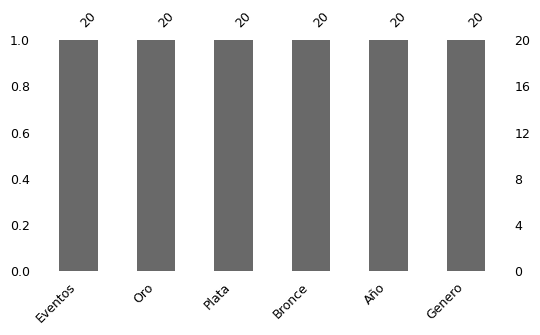

----------------------------------------------------------------------------------------------------
Missing-value pattern visualization:


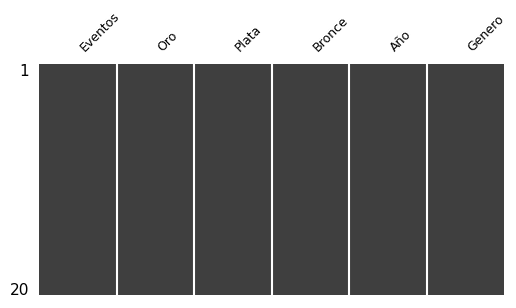

----------------------------------------------------------------------------------------------------
**************************************************
********************** 2021 **********************
**************************************************
How many missing values does each column contain?


Eventos    0
Oro        0
Plata      0
Bronce     0
Año        0
Genero     0
dtype: int64

----------------------------------------------------------------------------------------------------
What percentage of values is missing in each column?


,Col,pct
0,Eventos,0.0
1,Oro,0.0
2,Plata,0.0
3,Bronce,0.0
4,Año,0.0
5,Genero,0.0


----------------------------------------------------------------------------------------------------
Missing-value visualization:


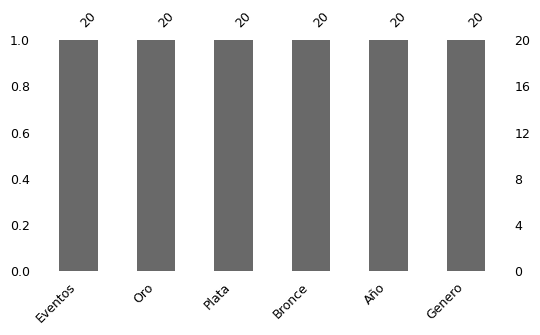

----------------------------------------------------------------------------------------------------
Missing-value pattern visualization:


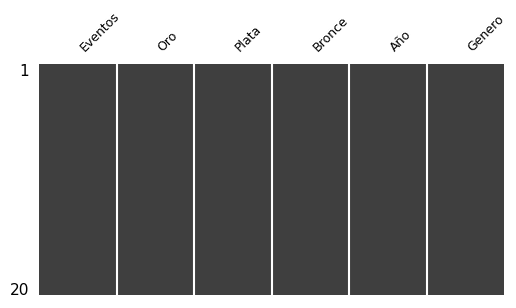

----------------------------------------------------------------------------------------------------


In [6]:
for name, df in df_dict.items():
    print('*'*50)
    print('*'*22, name, '*'*22)
    print('*'*50)
    fpf.exploracion_nulos(df)

### Duplicate records

In [7]:
for name, df in df_dict.items():
    print(f'{name} -> {df.duplicated().sum()} duplicate rows')

2019 -> 0 duplicate rows
2021 -> 0 duplicate rows


### Combine the supplied files

In [8]:
df = pd.concat([df_dict['2019'],df_dict['2021']], ignore_index=True)

In [9]:
df.Año.unique()

array([2019, 2021])

### Reshape medal columns into athlete records

Reshape the data to include event, year, gender, medal (gold, silver, or bronze), and athlete.

The source tables store medal winners in separate columns. Reshaping them creates one record per medal-winning athlete, with event, source-year label, gender, medal, and athlete text available for extraction.

In [10]:
df.head(2)

,Eventos,Oro,Plata,Bronce,Año,Genero
0,55 kg (06.04),Mirco Scarantino Italia 116 + 145 = 261[n 1]​,Anguel Rusev Bulgaria 110 + 146 = 256[n 1]​,Muammer Şahin Turquía 112 + 135 = 247[n 1]​,2019,Masculino
1,61 kg (07.04),Henadz Laptseu Bielorrusia 133 + 153 = 286,Bünyamin Sezer Turquía 132 + 151 = 283,Ferdi Hardal Turquía 127 + 155 = 282,2019,Masculino


In [11]:
df_melted = df.melt(id_vars=['Eventos','Año','Genero'], var_name='Medalla', value_name='Atleta')

In [12]:
df_melted.head(2)

,Eventos,Año,Genero,Medalla,Atleta
0,55 kg (06.04),2019,Masculino,Oro,Mirco Scarantino Italia 116 + 145 = 261[n 1]​
1,61 kg (07.04),2019,Masculino,Oro,Henadz Laptseu Bielorrusia 133 + 153 = 286


In [13]:
# During data preparation, we found artifacts to remove, such as the [2] footnote marker in an athlete cell.
df_melted[df_melted['Atleta'].str.contains('Valentín', na=False)]

,Eventos,Año,Genero,Medalla,Atleta
56,76 kg (11.04),2019,Femenino,Plata,Lidia Valentín[2]​ España 108 + 133 = 241


In [14]:
df_melted['Atleta'] = df_melted['Atleta'].str.replace(r'\[\d\]', '', regex=True)

In [15]:
# Some athlete cells also contain markers such as [n 1].
df_melted['Atleta'] = df_melted['Atleta'].str.replace(r'\[.\s*\d+\]', '', regex=True)


### Extract dates, categories, athletes, and results

- Date
- First name
- Last name
- Country
- Results
- Snatch
- Clean and jerk
- Total

In [16]:
df_melted.head(2)

,Eventos,Año,Genero,Medalla,Atleta
0,55 kg (06.04),2019,Masculino,Oro,Mirco Scarantino Italia 116 + 145 = 261​
1,61 kg (07.04),2019,Masculino,Oro,Henadz Laptseu Bielorrusia 133 + 153 = 286


In [17]:
# Create the date column
df_melted['Fecha'] = pd.to_datetime(df_melted.apply(lambda x:fpf.extraer_fecha(x), axis=1), format='%d/%m/%Y')

In [18]:
# Drop the year column
df_melted.drop(columns=['Año'], inplace=True)

In [19]:
# Create the weight-category column
df_melted['Categoria'] = df_melted['Eventos'].str.extract(r'(\+?\d+)\s*kg', expand=False)

In [20]:
# Drop the event column
df_melted.drop(columns=['Eventos'], inplace=True)

In [21]:
# Extract the athlete name, surname(s), and country from the athlete field
info_atleta = df_melted['Atleta'].str.extract(r'^(.*?)(?=\s*\d)')


In [22]:
# Names and countries may contain more than one word; inspect these cases before parsing.
# Identify edge cases
info_atleta[info_atleta[0].str.split().str.len() > 3]

,0
35,Emily Godley Reino Unido
39,Emily Campbell Reino Unido
55,Emily Godley Reino Unido
57,Anna Van Bellinghen Bélgica
74,Sarah Davies Reino Unido
94,Zoe Smith Reino Unido
99,Emily Campbell Reino Unido


In [23]:
# Create the first-name column 
df_melted['Nombre'] = info_atleta[0].str.split().str.get(0)

In [24]:
# Create the last-name column, accounting for known exceptions
df_melted['Apellido'] = info_atleta[0].apply(fpf.extraer_apellido)

In [25]:
# Create the country column, accounting for known exceptions
df_melted['Pais'] = info_atleta[0].apply(fpf.extraer_pais)

In [26]:
df_melted['Pais'].unique()

<ArrowStringArray>
[     'Italia', 'Bielorrusia',     'Francia',    'Bulgaria',     'Armenia',
     'Ucrania',     'Georgia',     'Turquía',     'Rumania',     'Polonia',
     'Letonia',       'Rusia',    'Alemania',  'Azerbaiyán', 'Reino Unido',
     'Albania',      'España',     'Bélgica',    'Moldavia',      'Suecia',
     'Austria']
Length: 21, dtype: str

In [27]:
resultados = df_melted['Atleta'].str.extract(r'(\d+)\s*\+\s*(\d+)\s*=\s*(\d+)\s*')
df_melted[['Arrancada','Dos Tiempos', 'Total']] = resultados

In [28]:
# Drop the athlete column
df_melted.drop(columns=['Atleta'], inplace=True)

In [29]:
df_melted.head()

,Genero,Medalla,Fecha,Categoria,Nombre,Apellido,Pais,Arrancada,Dos Tiempos,Total
0,Masculino,Oro,2019-04-06,55,Mirco,Scarantino,Italia,116,145,261
1,Masculino,Oro,2019-04-07,61,Henadz,Laptseu,Bielorrusia,133,153,286
2,Masculino,Oro,2019-04-08,67,Bernardin,Matam,Francia,137,175,312
3,Masculino,Oro,2019-04-09,73,Bozhidar,Andreev,Bulgaria,153,192,345
4,Masculino,Oro,2019-04-10,81,Antonino,Pizzolato,Italia,155,201,356


In [30]:
df_melted.sample(5)

,Genero,Medalla,Fecha,Categoria,Nombre,Apellido,Pais,Arrancada,Dos Tiempos,Total
53,Femenino,Plata,2019-04-08,59,Tatiana,Aleyeva,Rusia,94,120,214
106,Masculino,Bronce,2021-04-09,96,Hakob,Mkrtchian,Armenia,160,212,372
61,Masculino,Plata,2021-04-04,61,Shota,Mishvelidze,Georgia,135,155,290
11,Femenino,Oro,2019-04-06,49,Elena,Andrieș,Rumania,87,103,190
83,Masculino,Bronce,2019-04-09,73,Vadzim,Lijarad,Bielorrusia,153,182,335


### Arrange the analytical fields

**Analytical table fields**

| Gender | Category | Date | Medal | First name | Last name | Country | Snatch | Clean and jerk | Total |
|---|---|---|---|---|---|---|---|---|---|

In [31]:
orden_columnas = ['Genero', 'Categoria', 'Fecha', 'Medalla', 'Nombre', 'Apellido', 'Pais', 'Arrancada', 'Dos Tiempos', 'Total']
df_melted = df_melted[orden_columnas]

In [32]:
df_melted.head(2)

,Genero,Categoria,Fecha,Medalla,Nombre,Apellido,Pais,Arrancada,Dos Tiempos,Total
0,Masculino,55,2019-04-06,Oro,Mirco,Scarantino,Italia,116,145,261
1,Masculino,61,2019-04-07,Oro,Henadz,Laptseu,Bielorrusia,133,153,286


### Assign data types

**Data types used**

- Gender: `object`
- Category: `category`
- Date: `datetime64[ns]`
- Medal: `category`
- First name, last name, and country: `object`
- Snatch, clean and jerk, and total: `int64`

In [33]:
df_melted.dtypes

Genero                    str
Categoria                 str
Fecha          datetime64[us]
Medalla                   str
Nombre                 object
Apellido                  str
Pais                      str
Arrancada                 str
Dos Tiempos               str
Total                     str
dtype: object

In [34]:
# Convert the numeric columns
for col in ['Arrancada', 'Dos Tiempos', 'Total']:
    df_melted[col] = pd.to_numeric(df_melted[col], errors='coerce').astype('int64')

In [35]:
# Convert the remaining columns
df_melted = df_melted.astype({
    'Genero':'object',
    'Categoria':'category',
    'Fecha':'datetime64[ns]',
    'Medalla':'category',
    'Nombre': 'object',
    'Apellido':'object',
    'Pais':'object'
})

In [36]:
df_melted.dtypes

Genero                 object
Categoria            category
Fecha          datetime64[ns]
Medalla              category
Nombre                 object
Apellido               object
Pais                   object
Arrancada               int64
Dos Tiempos             int64
Total                   int64
dtype: object

### Order the analytical table

Sort records by gender, weight category, date, and medal. Open-ended classes retain the `+` sign, so `87` and `+87`, or `109` and `+109`, remain distinct. Categories are ordered by their numeric limit, with the open-ended class after the standard class at the same limit.

In [37]:
# Keep standard and open-ended classes distinct (for example, 87 and +87).
category_order = sorted(
    df_melted['Categoria'].dropna().unique(),
    key=lambda category: (int(category.lstrip('+')), category.startswith('+'))
)
df_melted['Categoria'] = pd.Categorical(
    df_melted['Categoria'], categories=category_order, ordered=True
)

# Define the medal order
orden_medalla = ['Oro', 'Plata', 'Bronce']
df_melted['Medalla'] = pd.Categorical(df_melted['Medalla'], categories=orden_medalla, ordered=True)

# Sort the dataframe, including chronological order
df_final = df_melted.sort_values(['Genero', 'Categoria', 'Fecha', 'Medalla'], ascending=[True, True, True, True],ignore_index=True)

df_final['Categoria'] =df_final['Categoria'].astype('category')

In [38]:
df_final

,Genero,Categoria,Fecha,Medalla,Nombre,Apellido,Pais,Arrancada,Dos Tiempos,Total
0,Femenino,45,2019-04-06,Oro,Şaziye,Erdoğan,Turquía,75,88,163
1,Femenino,45,2019-04-06,Plata,Ivana,Petrova,Bulgaria,69,89,158
2,Femenino,45,2019-04-06,Bronce,Yuliya,Asayonak,Bielorrusia,69,81,150
3,Femenino,45,2021-04-03,Oro,Nadezhda,Nguen,Bulgaria,72,83,155
4,Femenino,45,2021-04-03,Plata,Ivana,Petrova,Bulgaria,67,85,152
...,...,...,...,...,...,...,...,...,...,...
115,Masculino,+109,2019-04-13,Plata,Irakli,Turmanidze,Georgia,206,241,447
116,Masculino,+109,2019-04-13,Bronce,Ruben,Alexanian,Armenia,195,245,440
117,Masculino,+109,2021-04-11,Oro,Lasha,Talajadze,Georgia,222,263,485
118,Masculino,+109,2021-04-11,Plata,Gor,Minasian,Armenia,216,248,464


## 3. Performance patterns in the supplied results

What is the shape (dimensions) of the dataframe?


'The dataframe has 120 rows and 10 columns'

----------------------------------------------------------------------------------------------------
What are the first five rows of the dataframe?


,Genero,Categoria,Fecha,Medalla,Nombre,Apellido,Pais,Arrancada,Dos Tiempos,Total
0,Femenino,45,2019-04-06,Oro,Şaziye,Erdoğan,Turquía,75,88,163
1,Femenino,45,2019-04-06,Plata,Ivana,Petrova,Bulgaria,69,89,158
2,Femenino,45,2019-04-06,Bronce,Yuliya,Asayonak,Bielorrusia,69,81,150
3,Femenino,45,2021-04-03,Oro,Nadezhda,Nguen,Bulgaria,72,83,155
4,Femenino,45,2021-04-03,Plata,Ivana,Petrova,Bulgaria,67,85,152


----------------------------------------------------------------------------------------------------
What is a random sample of 5 rows from the dataframe?


...

----------------------------------------------------------------------------------------------------
How many missing values does each column contain?


Genero         0
Categoria      0
Fecha          0
Medalla        0
Nombre         0
Apellido       0
Pais           0
Arrancada      0
Dos Tiempos    0
Total          0
dtype: int64

----------------------------------------------------------------------------------------------------
What percentage of values is missing in each column?


,Col,pct
0,Genero,0.0
1,Categoria,0.0
2,Fecha,0.0
3,Medalla,0.0
4,Nombre,0.0
5,Apellido,0.0
6,Pais,0.0
7,Arrancada,0.0
8,Dos Tiempos,0.0
9,Total,0.0


----------------------------------------------------------------------------------------------------
Missing-value visualization:


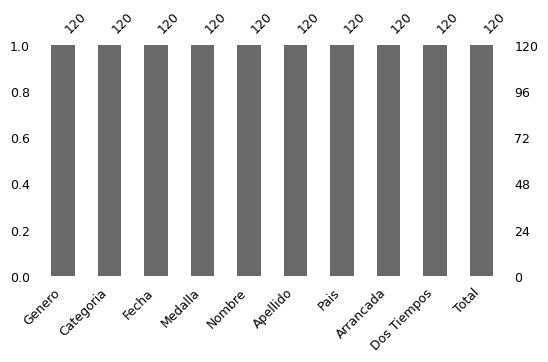

----------------------------------------------------------------------------------------------------
Missing-value pattern visualization:


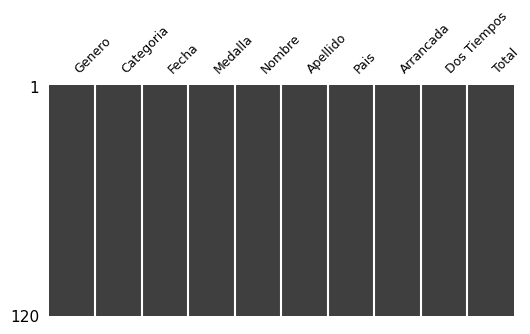

----------------------------------------------------------------------------------------------------


In [39]:
# Repeat basic and missing-value exploration on the final dataset
fpf.exploracion_basica(df_final)
fpf.exploracion_nulos(df_final)

### Dataset overview
The supplied files produce 120 medal records from the 2019 and 2021 editions. The 2020 filename is retained as an original source label; the analytical dates use 2021.

In [40]:
# How many unique weight categories are there for each gender?
df_final.groupby('Genero')['Categoria'].nunique()

Genero
Femenino     10
Masculino    10
Name: Categoria, dtype: int64

### Weight categories
The source data contains ten distinct weight categories for each gender when open-ended classes are kept separate.

In [41]:
# What are the overall mean snatch, clean-and-jerk, and total results by gender?
df_resultados_por_genero = df_final.groupby('Genero').agg({
    'Arrancada':'mean',
    'Dos Tiempos':'mean',
    'Total':'mean',
}).round(2)
df_resultados_por_genero

,Arrancada,Dos Tiempos,Total
Genero,,,
Femenino,97.98,120.38,218.37
Masculino,161.22,194.40,355.62


### Average results by gender
The saved averages are higher for male athletes than female athletes across the three lifting measures. The groups compete across different body-weight ranges.

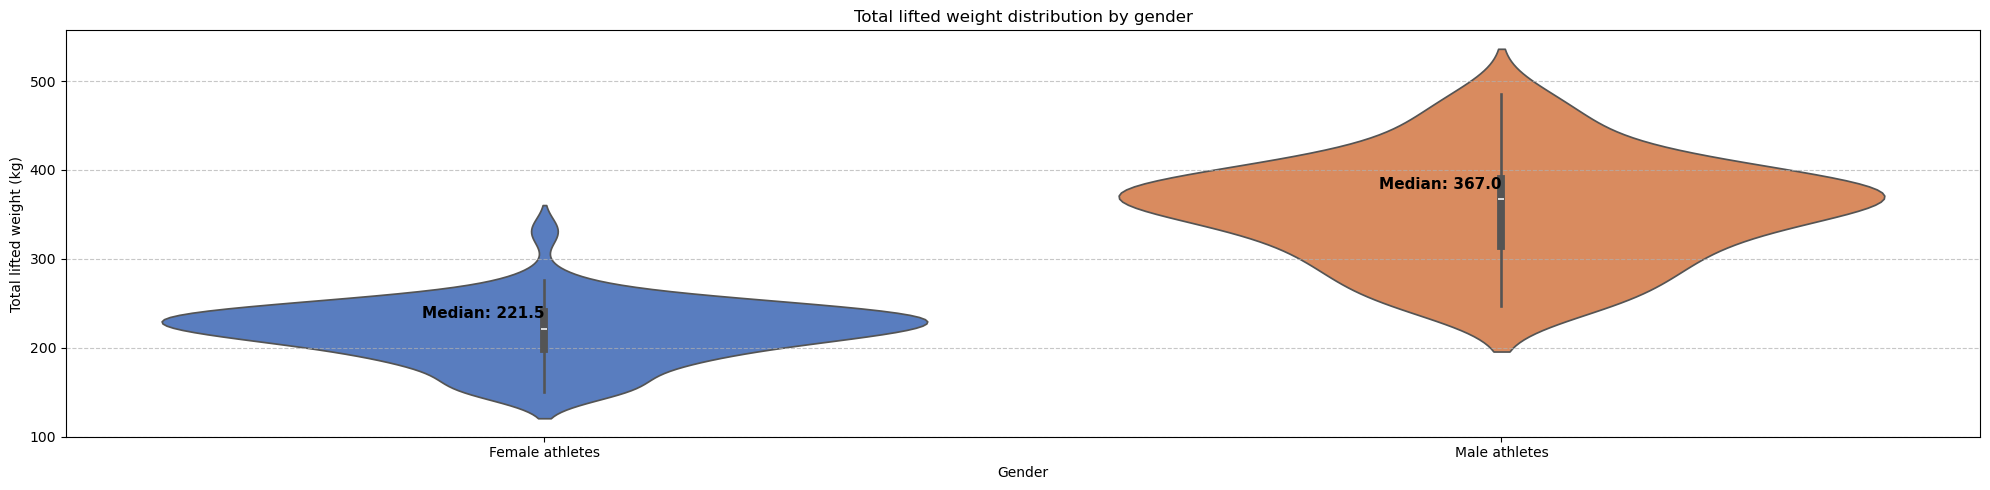

In [42]:
# How is total lifted weight distributed by gender?
fig, ax = plt.subplots(figsize = (20, 5))
sns.violinplot(
    data = df_final,
    x = 'Genero',
    y = 'Total',
    hue='Genero',
    palette='muted'
)

ax.set(
    title = 'Total lifted weight distribution by gender',
    xlabel = 'Gender',
    ylabel = 'Total lifted weight (kg)',
)

ax.grid(axis='y', linestyle='--', alpha=0.7)

medianas = df_final.groupby('Genero')['Total'].median()

for i, genero in enumerate(['Femenino', 'Masculino']):
    valor_mediana = medianas[genero]
    ax.text(
        x = i,                     
        y = valor_mediana + 12,    
        s = f"Median: {valor_mediana:.1f}",
        color = "black",           
        ha = "right",             
        fontweight = "bold",       
        fontsize = 11              
    )
ax.set_xticks(ax.get_xticks(), labels=['Female athletes', 'Male athletes'])
plt.tight_layout()


### Distribution of total lifted weight
The violin plot shows different total-weight distributions and several peaks that may correspond to the weight categories.

In [43]:
# What are the average snatch, clean-and-jerk, and total results by gender and category?
df_genero_categoria =df_final.groupby(['Genero','Categoria']).agg({
    'Arrancada':'mean',
    'Dos Tiempos':'mean',
    'Total':'mean',
})

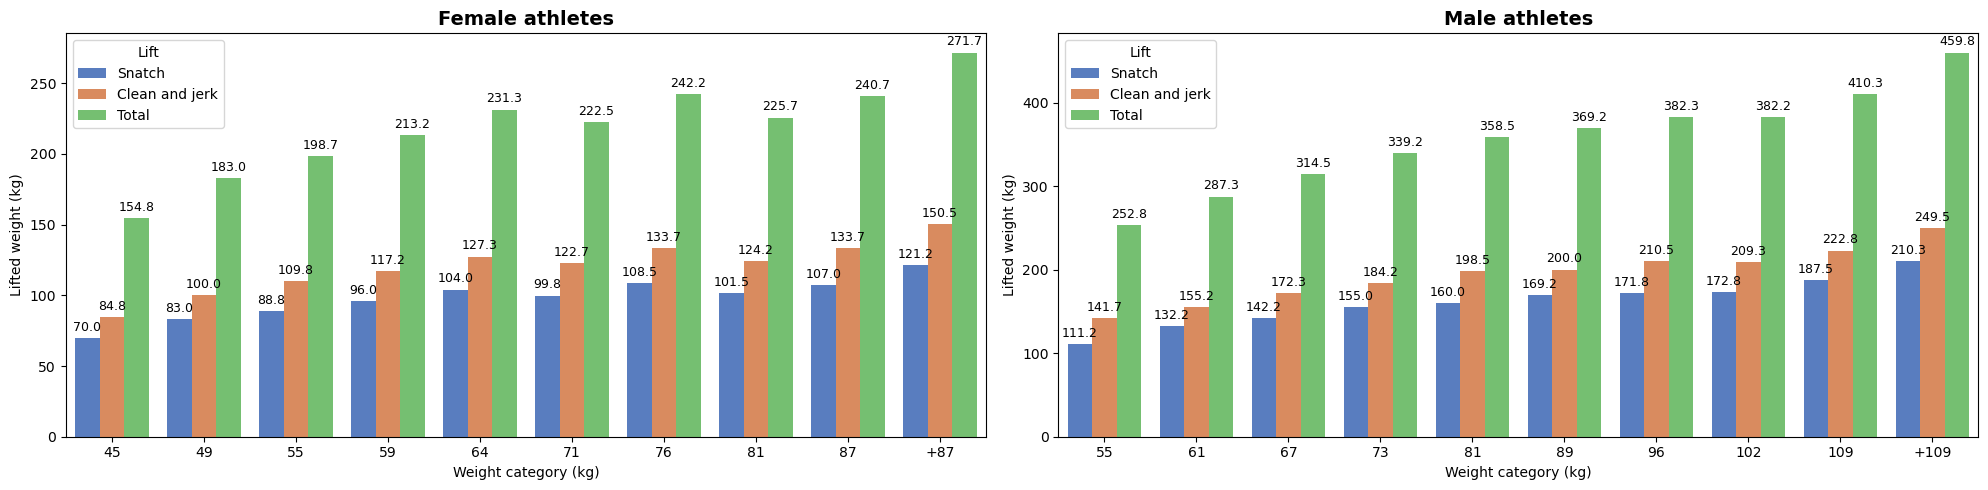

In [44]:
fig, ax = plt.subplots(1,2 , figsize=(20,5))

# Plot the results for female athletes
df_femenino = df_genero_categoria.query('Genero == "Femenino"').reset_index()
df_femenino['Categoria'] = df_femenino['Categoria'].cat.remove_unused_categories()

df_melted = pd.melt(
    df_femenino, 
    id_vars=['Categoria'], 
    value_vars=['Arrancada', 'Dos Tiempos', 'Total'],
    var_name='Lift', 
    value_name='Kilos'
)

sns.barplot(data = df_melted, x='Categoria', y='Kilos', hue='Lift', palette="muted", ax=ax[0])
ax[0].set_title('Female athletes', fontsize=14, fontweight='bold')

for container in ax[0].containers:
    ax[0].bar_label(container, fmt='%.1f', padding=3, fontsize=9)

# Plot the results for male athletes
df_masculino = df_genero_categoria.query('Genero == "Masculino"').reset_index()
df_masculino['Categoria'] = df_masculino['Categoria'].cat.remove_unused_categories()

df_melted = pd.melt(
    df_masculino, 
    id_vars=['Categoria'], 
    value_vars=['Arrancada', 'Dos Tiempos', 'Total'],
    var_name='Lift', 
    value_name='Kilos'
)

sns.barplot(data = df_melted, x='Categoria', y='Kilos', hue='Lift', palette="muted", ax=ax[1])
ax[1].set_title('Male athletes', fontsize=14, fontweight='bold')

for container in ax[1].containers:
    ax[1].bar_label(container, fmt='%.1f', padding=3, fontsize=9)
for panel in ax:
    panel.set_xlabel('Weight category (kg)')
    panel.set_ylabel('Lifted weight (kg)')
    handles, labels = panel.get_legend_handles_labels()
    panel.legend(handles, ['Snatch', 'Clean and jerk', 'Total'], title='Lift')
plt.tight_layout()


The standard and open-ended classes are separate in this comparison, including 87/+87 and 109/+109.

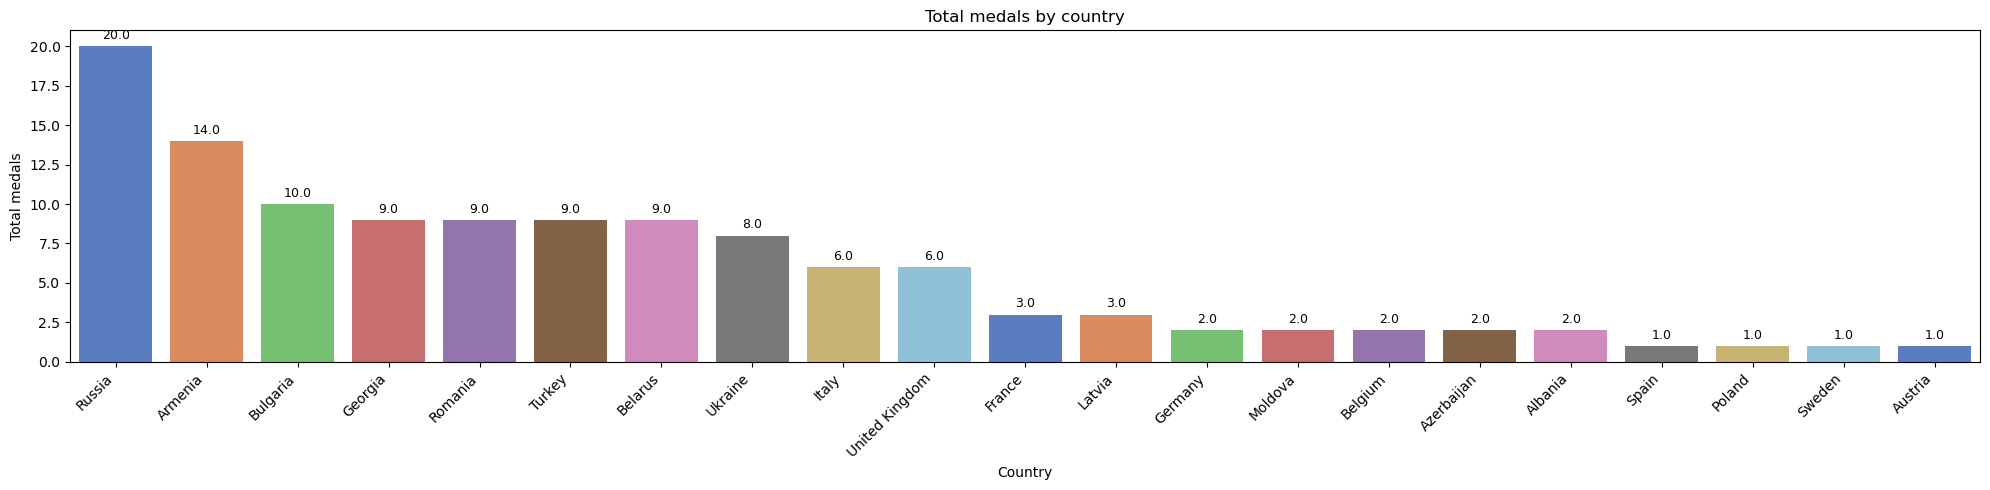

In [45]:
# How many total medals did each country win?
df_medallas_totales_pais = df_final.groupby('Pais')['Medalla'].count().sort_values(ascending=False).reset_index()

fig, ax = plt.subplots(figsize = (20, 5))
sns.barplot(
    data = df_medallas_totales_pais,
    x = 'Pais',
    y = 'Medalla',
    hue='Pais',
    palette="muted"
)

ax.set(
    title = 'Total medals by country',
    xlabel = 'Country',
    ylabel = 'Total medals',
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3, fontsize=9)

ax.set_xticks(ax.get_xticks(), labels=[country_labels.get(t.get_text(), t.get_text()) for t in ax.get_xticklabels()], rotation=45, ha='right')
plt.tight_layout()


### Country medal totals
Russia leads the combined Phase 1 medal table with 20 medals, followed by Armenia (14) and Bulgaria (10).

## 4. Country comparisons in the supplied results

### How many gold, silver, and bronze medals did each country win, regardless of gender?

In [46]:
df_medallas_pais = pd.crosstab(df_final['Pais'], df_final['Medalla'])
df_medallas_pais['Total'] = df_medallas_pais['Oro'] + df_medallas_pais['Plata'] + df_medallas_pais['Bronce']
df_medallas_pais = df_medallas_pais.sort_values(by='Total', ascending = False)
df_medallas_pais


Medalla,Oro,Plata,Bronce,Total
Pais,,,,
Rusia,4,9,7,20
Armenia,4,3,7,14
Bulgaria,4,5,1,10
Georgia,3,4,2,9
Rumania,4,2,3,9
Turquía,3,1,5,9
Bielorrusia,3,3,3,9
Ucrania,5,2,1,8
Italia,3,2,1,6


Russia has the most medals in the supplied 2019/2021 source records (20), followed by Armenia (14). Ukraine has the most gold medals (5). Results use the supplied historical source version.

### Which country has the most balanced medal success across female and male athletes?

In [47]:
df_diff_medalla = pd.crosstab(df_final['Pais'], df_final['Genero'], values=df_final['Medalla'], aggfunc='count').fillna(0)
df_diff_medalla['Diferencia'] = (df_diff_medalla['Femenino'] - df_diff_medalla['Masculino']).abs()
df_diff_medalla.sort_values(by='Diferencia')

Genero,Femenino,Masculino,Diferencia
Pais,,,
Alemania,1.0,1.0,0.0
Azerbaiyán,1.0,1.0,0.0
Moldavia,1.0,1.0,0.0
Suecia,1.0,0.0,1.0
Austria,1.0,0.0,1.0
Polonia,1.0,0.0,1.0
Letonia,1.0,2.0,1.0
España,1.0,0.0,1.0
Francia,2.0,1.0,1.0


The saved result identifies Germany, Azerbaijan, and Moldova as having equal medal counts across genders in Phase 1.

### Which country has the smallest difference in mean total weight lifted by female and male athletes?

In [48]:
df_pais_genero = pd.crosstab(
    index=df_final['Pais'], 
    columns=df_final['Genero'], 
    values=df_final['Total'], 
    aggfunc='mean'
).fillna(0)

In [49]:
# Keep countries represented in both gender groups
df_pais_genero = df_pais_genero[(df_pais_genero['Femenino'] != 0) & (df_pais_genero['Masculino'] != 0)]

In [50]:
# Calculate the absolute difference
df_pais_genero['Diferencia'] = (df_pais_genero['Masculino'] - df_pais_genero['Femenino']).abs()
df_pais_genero = df_pais_genero.rename_axis(columns = '')
solucion = df_pais_genero['Diferencia'].idxmin().upper()

In [51]:
# Report the result using English display labels.
print(f'The country with the smallest difference in mean total lifted weight between female and male medallists is {country_labels.get(solucion.title(), solucion.title())}.')

The country with the smallest difference in mean total lifted weight between female and male medallists is Romania.


## 5. Extending the sources with web scraping

### Scraping libraries

In [52]:
import requests
from io import StringIO

### Retrieve and parse the championship tables

In [53]:
http_status_codes = {
    200: "OK: the requested page was returned.",
    301: "Moved permanently.",
    302: "Temporary redirect.",
    401: "Authentication required.",
    403: "Access forbidden.",
    404: "Page not found.",
    500: "Internal server error.",
    503: "Service unavailable."
}

In [54]:
url_dict = {
            '2021' : 'https://es.wikipedia.org/wiki/Campeonato_Europeo_de_Halterofilia_de_2021',
            '2022' : 'https://es.wikipedia.org/wiki/Campeonato_Europeo_de_Halterofilia_de_2022',
            '2023' : 'https://es.wikipedia.org/wiki/Campeonato_Europeo_de_Halterofilia_de_2023',
            '2024' : 'https://es.wikipedia.org/wiki/Campeonato_Europeo_de_Halterofilia_de_2024'
}

headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/58.0.3029.110 Safari/537.3'
}

page_dict = {}
for year, url in url_dict.items():
    page_dict[year] = requests.get(url, headers=headers, timeout=30)

for page in page_dict.values():
    print(page.status_code, http_status_codes.get(page.status_code, "Unexpected HTTP status"))
    page.raise_for_status()

200 OK: the requested page was returned.
200 OK: the requested page was returned.
200 OK: the requested page was returned.
200 OK: the requested page was returned.


In [55]:
html_dict = {}
for year, page in page_dict.items():
    html_dict[year] = page.text

table_dict = {}
for year, html in html_dict.items(): 
    table_dict[year] = pd.read_html(StringIO(html))


In [56]:
# Which tables do we need?
#for year, tablas in table_dict.items():
#     print a heading for each year’s tables
#    for tabla in tablas: 
 #       display(tabla.head(3))

In [57]:
# The third table for each year contains the men’s results; the fourth contains the women’s results.
# Standardize the scraped tables. Keep the supplied 2021 source version once.
for year, tablas in table_dict.items():
    if year in df_dict:
        print(f"{year}: already represented by the supplied file; not added twice.")
        continue
    df_masculino = tablas[2]
    df_masculino['Genero'] = 'Masculino'
    df_masculino['Año'] = year
    df_masculino = df_masculino.rename(columns = {
        'Unnamed: 1' : 'Oro',
        'Unnamed: 2' : 'Plata',
        'Unnamed: 3' : 'Bronce',
        'Evento' : 'Eventos'
    })
    df_femenino = tablas[3]
    df_femenino['Genero'] = 'Femenino'
    df_femenino['Año'] = year
    df_femenino = df_femenino.rename(columns = {
        'Unnamed: 1' : 'Oro',
        'Unnamed: 2' : 'Plata',
        'Unnamed: 3' : 'Bronce',
        'Evento' : 'Eventos'
    })
    df_dict[year] = pd.concat([df_masculino, df_femenino], ignore_index=True)
    df_dict[year] = df_dict[year][['Eventos', 'Oro', 'Plata', 'Bronce', 'Año', 'Genero']]

    

2021: already represented by the supplied file; not added twice.


In [58]:
df_dict.keys()

dict_keys(['2019', '2021', '2022', '2023', '2024'])

## 6. Preparing the combined results

### Dataset structure

In [59]:
for name, df in df_dict.items():
    print('*'*50)
    print('*'*22, name, '*'*22)
    print('*'*50)
    fpf.exploracion_basica(df)

**************************************************
********************** 2019 **********************
**************************************************
What is the shape (dimensions) of the dataframe?


'The dataframe has 20 rows and 6 columns'

----------------------------------------------------------------------------------------------------
What are the first five rows of the dataframe?


,Eventos,Oro,Plata,Bronce,Año,Genero
0,55 kg (06.04),Mirco Scarantino Italia 116 + 145 = 261[n 1]​,Anguel Rusev Bulgaria 110 + 146 = 256[n 1]​,Muammer Şahin Turquía 112 + 135 = 247[n 1]​,2019,Masculino
1,61 kg (07.04),Henadz Laptseu Bielorrusia 133 + 153 = 286,Bünyamin Sezer Turquía 132 + 151 = 283,Ferdi Hardal Turquía 127 + 155 = 282,2019,Masculino
2,67 kg (08.04),Bernardin Matam Francia 137 + 175 = 312,Simon Brandhuber Alemania 146 + 165 = 311,Goga Chjeidze Georgia 139 + 169 = 308,2019,Masculino
3,73 kg (09.04),Bozhidar Andreev Bulgaria 153 + 192 = 345,Briken Calja Albania 156 + 183 = 339,Vadzim Lijarad Bielorrusia 153 + 182 = 335,2019,Masculino
4,81 kg (10.04),Antonino Pizzolato Italia 155 + 201 = 356,Piotr Asayonak Bielorrusia 159 + 196 = 355,Ritvars Suharevs Letonia 162 + 192 = 354,2019,Masculino


----------------------------------------------------------------------------------------------------
What is a random sample of 5 rows from the dataframe?


...

----------------------------------------------------------------------------------------------------
How many unique values does each column contain?


Año         1
Genero      2
Eventos    19
Oro        20
Plata      20
Bronce     20
dtype: int64

----------------------------------------------------------------------------------------------------
What unique values does each column contain?


,0
Eventos,"[55 kg (13.02), 61 kg (13.02), 67 kg (14.02), ..."
Oro,"[Anguel Rusev Bulgaria 109 + 135 = 244[n 1], ..."
Plata,[Ramin Shamilishvili Georgia 111 + 130 = 241[...
Bronce,"[Dzhan Zarkov Bulgaria 102 + 133 = 235[n 1], ..."
Año,[2024]
Genero,"[Masculino, Femenino]"


----------------------------------------------------------------------------------------------------


### Missing values

**************************************************
********************** 2019 **********************
**************************************************
How many missing values does each column contain?


Eventos    0
Oro        0
Plata      0
Bronce     0
Año        0
Genero     0
dtype: int64

----------------------------------------------------------------------------------------------------
What percentage of values is missing in each column?


,Col,pct
0,Eventos,0.0
1,Oro,0.0
2,Plata,0.0
3,Bronce,0.0
4,Año,0.0
5,Genero,0.0


----------------------------------------------------------------------------------------------------
Missing-value visualization:


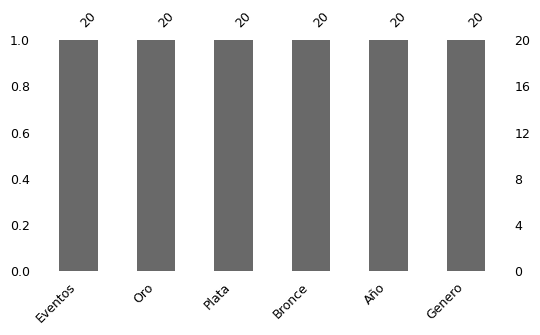

----------------------------------------------------------------------------------------------------
Missing-value pattern visualization:


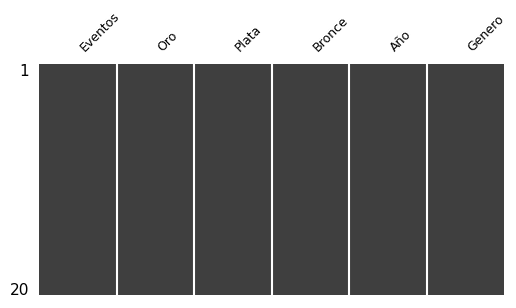

----------------------------------------------------------------------------------------------------
**************************************************
********************** 2021 **********************
**************************************************
How many missing values does each column contain?


Eventos    0
Oro        0
Plata      0
Bronce     0
Año        0
Genero     0
dtype: int64

----------------------------------------------------------------------------------------------------
What percentage of values is missing in each column?


,Col,pct
0,Eventos,0.0
1,Oro,0.0
2,Plata,0.0
3,Bronce,0.0
4,Año,0.0
5,Genero,0.0


----------------------------------------------------------------------------------------------------
Missing-value visualization:


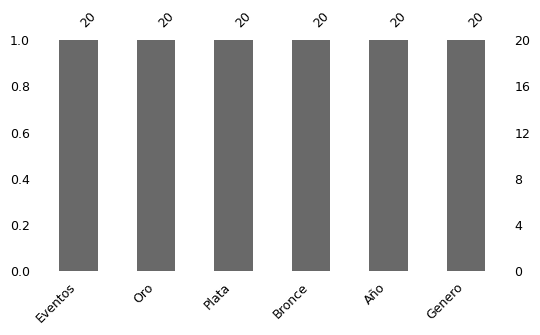

----------------------------------------------------------------------------------------------------
Missing-value pattern visualization:


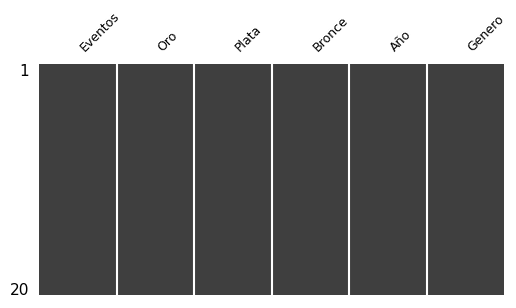

----------------------------------------------------------------------------------------------------
**************************************************
********************** 2022 **********************
**************************************************
How many missing values does each column contain?


Eventos    0
Oro        0
Plata      0
Bronce     0
Año        0
Genero     0
dtype: int64

----------------------------------------------------------------------------------------------------
What percentage of values is missing in each column?


,Col,pct
0,Eventos,0.0
1,Oro,0.0
2,Plata,0.0
3,Bronce,0.0
4,Año,0.0
5,Genero,0.0


----------------------------------------------------------------------------------------------------
Missing-value visualization:


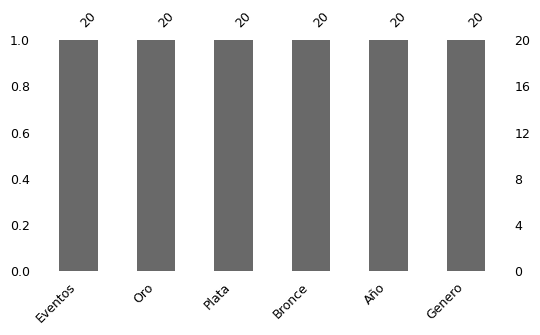

----------------------------------------------------------------------------------------------------
Missing-value pattern visualization:


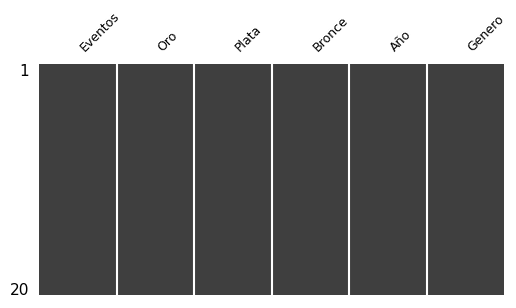

----------------------------------------------------------------------------------------------------
**************************************************
********************** 2023 **********************
**************************************************
How many missing values does each column contain?


Eventos    0
Oro        0
Plata      0
Bronce     0
Año        0
Genero     0
dtype: int64

----------------------------------------------------------------------------------------------------
What percentage of values is missing in each column?


,Col,pct
0,Eventos,0.0
1,Oro,0.0
2,Plata,0.0
3,Bronce,0.0
4,Año,0.0
5,Genero,0.0


----------------------------------------------------------------------------------------------------
Missing-value visualization:


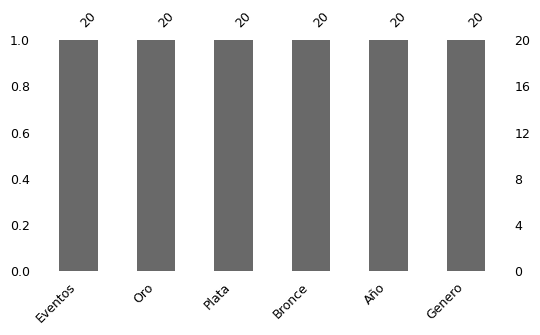

----------------------------------------------------------------------------------------------------
Missing-value pattern visualization:


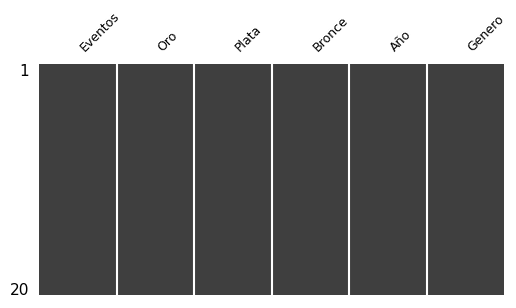

----------------------------------------------------------------------------------------------------
**************************************************
********************** 2024 **********************
**************************************************
How many missing values does each column contain?


Eventos    0
Oro        0
Plata      0
Bronce     0
Año        0
Genero     0
dtype: int64

----------------------------------------------------------------------------------------------------
What percentage of values is missing in each column?


,Col,pct
0,Eventos,0.0
1,Oro,0.0
2,Plata,0.0
3,Bronce,0.0
4,Año,0.0
5,Genero,0.0


----------------------------------------------------------------------------------------------------
Missing-value visualization:


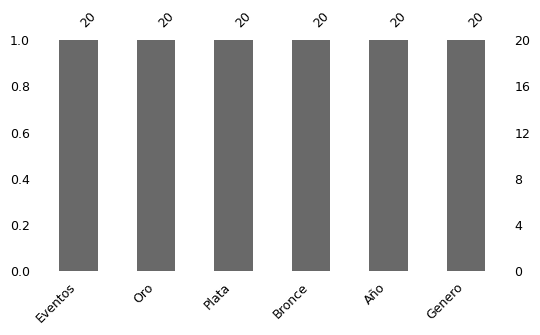

----------------------------------------------------------------------------------------------------
Missing-value pattern visualization:


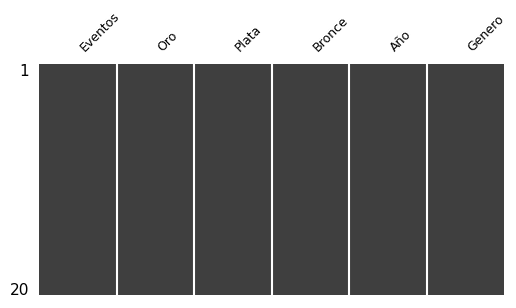

----------------------------------------------------------------------------------------------------


In [60]:
for name, df in df_dict.items():
    print('*'*50)
    print('*'*22, name, '*'*22)
    print('*'*50)
    fpf.exploracion_nulos(df)

### Duplicate records

In [61]:
for name, df in df_dict.items():
    print(f'{name} -> {df.duplicated().sum()} duplicate rows')

2019 -> 0 duplicate rows
2021 -> 0 duplicate rows
2022 -> 0 duplicate rows
2023 -> 0 duplicate rows
2024 -> 0 duplicate rows


### Combine the supplied and scraped files

In [62]:
df = pd.concat([df_dict['2019'],df_dict['2021'],df_dict['2022'],df_dict['2023'],df_dict['2024']], ignore_index=True)

### Reshape medal columns into athlete records

Reshape the data to include event, year, gender, medal (gold, silver, or bronze), and athlete.

The source tables store medal winners in separate columns. Reshaping them creates one record per medal-winning athlete, with event, source-year label, gender, medal, and athlete text available for extraction.

In [63]:
df_melted = df.melt(id_vars=['Eventos','Año','Genero'], var_name='Medalla', value_name='Atleta')

In [64]:
df_melted.head(2)

,Eventos,Año,Genero,Medalla,Atleta
0,55 kg (06.04),2019,Masculino,Oro,Mirco Scarantino Italia 116 + 145 = 261[n 1]​
1,61 kg (07.04),2019,Masculino,Oro,Henadz Laptseu Bielorrusia 133 + 153 = 286


In [65]:
# Clean the extracted text
df_melted['Atleta'] = df_melted['Atleta'].str.replace(r'\[\d\]', '', regex=True)
df_melted['Atleta'] = df_melted['Atleta'].str.replace(r'\[.\s*\d+\]', '', regex=True)

### Extract dates, categories, athletes, and results

- Date
- First name
- Last name
- Country
- Results
- Snatch
- Clean and jerk
- Total

In [66]:
# Create the date column
df_melted['Fecha'] = pd.to_datetime(df_melted.apply(lambda x:fpf.extraer_fecha(x), axis=1), format='%d/%m/%Y')

In [67]:
# Drop the year column
df_melted.drop(columns=['Año'], inplace=True)

In [68]:
# Create the weight-category column
df_melted['Categoria'] = df_melted['Eventos'].str.extract(r'(\+?\d+)\s*kg', expand=False)

In [69]:
# Drop the event column
df_melted.drop(columns=['Eventos'], inplace=True)

In [70]:
# Extract the athlete name, surname(s), and country from the athlete field
info_atleta = df_melted['Atleta'].str.extract(r'^(.*?)(?=\s*\d)')

In [71]:
# Look for additional edge cases to update the parsing functions.
info_atleta[info_atleta[0].str.split().str.len() > 3]

,0
35,Emily Godley Reino Unido
39,Emily Campbell Reino Unido
59,Emily Campbell Reino Unido
64,Oscar Reyes Martínez Italia
79,Emily Campbell Reino Unido
84,Oscar Reyes Martínez Italia
96,Genna Toko Kegne Italia
99,Emily Campbell Reino Unido
115,Emily Godley Reino Unido
117,Anna Van Bellinghen Bélgica


In [72]:
# Create the first-name column 
df_melted['Nombre'] = info_atleta[0].str.split().str.get(0)

In [73]:
# Create the last-name column, accounting for known exceptions
df_melted['Apellido'] = info_atleta[0].apply(fpf.extraer_apellido)

In [74]:
# Create the country column, accounting for known exceptions
df_melted['Pais'] = info_atleta[0].apply(fpf.extraer_pais)

In [75]:
df_melted.Pais.unique()

<ArrowStringArray>
[     'Italia', 'Bielorrusia',     'Francia',    'Bulgaria',     'Armenia',
     'Ucrania',     'Georgia',     'Turquía',     'Rumania',     'Polonia',
     'Letonia',       'Rusia',    'Alemania',  'Azerbaiyán', 'Reino Unido',
      'Suecia',     'Noruega',         'AIN',     'Albania',      'España',
     'Bélgica',    'Moldavia',      'Israel',     'Austria',      'Serbia',
     'Irlanda',   'Finlandia']
Length: 27, dtype: str

In [76]:
resultados = df_melted['Atleta'].str.extract(r'(\d+)\s*\+\s*(\d+)\s*=\s*(\d+)\s*')
df_melted[['Arrancada','Dos Tiempos', 'Total']] = resultados

In [77]:
# Drop the athlete column
df_melted.drop(columns=['Atleta'], inplace=True)

In [78]:
df_melted.head()

,Genero,Medalla,Fecha,Categoria,Nombre,Apellido,Pais,Arrancada,Dos Tiempos,Total
0,Masculino,Oro,2019-04-06,55,Mirco,Scarantino,Italia,116,145,261
1,Masculino,Oro,2019-04-07,61,Henadz,Laptseu,Bielorrusia,133,153,286
2,Masculino,Oro,2019-04-08,67,Bernardin,Matam,Francia,137,175,312
3,Masculino,Oro,2019-04-09,73,Bozhidar,Andreev,Bulgaria,153,192,345
4,Masculino,Oro,2019-04-10,81,Antonino,Pizzolato,Italia,155,201,356


In [79]:
df_melted.sample(5)

,Genero,Medalla,Fecha,Categoria,Nombre,Apellido,Pais,Arrancada,Dos Tiempos,Total
27,Masculino,Oro,2021-04-10,102,Samvel,Gasparian,Armenia,176,214,390
107,Masculino,Plata,2019-04-13,102,Samvel,Gasparian,Armenia,168,209,377
82,Masculino,Oro,2024-02-14,67,Gor,Sahakian,Armenia,140,171,311
11,Femenino,Oro,2019-04-06,49,Elena,Andrieș,Rumania,87,103,190
177,Femenino,Plata,2023-04-21,81,Dilara,Narin,Turquía,101,134,235


### Arrange the analytical fields

**Analytical table fields**

| Gender | Category | Date | Medal | First name | Last name | Country | Snatch | Clean and jerk | Total |
|---|---|---|---|---|---|---|---|---|---|

In [80]:
orden_columnas = ['Genero', 'Categoria', 'Fecha', 'Medalla', 'Nombre', 'Apellido', 'Pais', 'Arrancada', 'Dos Tiempos', 'Total']
df_melted = df_melted[orden_columnas]

In [81]:
df_melted.head(2)

,Genero,Categoria,Fecha,Medalla,Nombre,Apellido,Pais,Arrancada,Dos Tiempos,Total
0,Masculino,55,2019-04-06,Oro,Mirco,Scarantino,Italia,116,145,261
1,Masculino,61,2019-04-07,Oro,Henadz,Laptseu,Bielorrusia,133,153,286


### Assign data types

**Data types used**

- Gender: `object`
- Category: `category`
- Date: `datetime64[ns]`
- Medal: `category`
- First name, last name, and country: `object`
- Snatch, clean and jerk, and total: `int64`

In [82]:
df_melted.dtypes

Genero                    str
Categoria                 str
Fecha          datetime64[us]
Medalla                   str
Nombre                 object
Apellido                  str
Pais                      str
Arrancada                 str
Dos Tiempos               str
Total                     str
dtype: object

In [83]:
# Convert the numeric columns
for col in ['Arrancada', 'Dos Tiempos', 'Total']:
    df_melted[col] = pd.to_numeric(df_melted[col], errors='coerce').astype('int64')

In [84]:
# Convert the remaining columns
df_melted = df_melted.astype({
    'Genero':'object',
    'Categoria':'category',
    'Fecha':'datetime64[ns]',
    'Medalla':'category',
    'Nombre': 'object',
    'Apellido':'object',
    'Pais':'object'
})

In [85]:
df_melted.dtypes

Genero                 object
Categoria            category
Fecha          datetime64[ns]
Medalla              category
Nombre                 object
Apellido               object
Pais                   object
Arrancada               int64
Dos Tiempos             int64
Total                   int64
dtype: object

### Order the analytical table

Sort records by gender, weight category, date, and medal. Open-ended classes retain the `+` sign, so `87` and `+87`, or `109` and `+109`, remain distinct. Categories are ordered by their numeric limit, with the open-ended class after the standard class at the same limit.

In [86]:
# Keep standard and open-ended classes distinct (for example, 87 and +87).
category_order = sorted(
    df_melted['Categoria'].dropna().unique(),
    key=lambda category: (int(category.lstrip('+')), category.startswith('+'))
)
df_melted['Categoria'] = pd.Categorical(
    df_melted['Categoria'], categories=category_order, ordered=True
)

# Define the medal order
orden_medalla = ['Oro', 'Plata', 'Bronce']
df_melted['Medalla'] = pd.Categorical(df_melted['Medalla'], categories=orden_medalla, ordered=True)

# Sort the dataframe, including chronological order
df_final = df_melted.sort_values(['Genero', 'Categoria', 'Fecha', 'Medalla'], ascending=[True, True, True, True],ignore_index=True)

df_final['Categoria'] =df_final['Categoria'].astype('category')

In [87]:
df_final

,Genero,Categoria,Fecha,Medalla,Nombre,Apellido,Pais,Arrancada,Dos Tiempos,Total
0,Femenino,45,2019-04-06,Oro,Şaziye,Erdoğan,Turquía,75,88,163
1,Femenino,45,2019-04-06,Plata,Ivana,Petrova,Bulgaria,69,89,158
2,Femenino,45,2019-04-06,Bronce,Yuliya,Asayonak,Bielorrusia,69,81,150
3,Femenino,45,2021-04-03,Oro,Nadezhda,Nguen,Bulgaria,72,83,155
4,Femenino,45,2021-04-03,Plata,Ivana,Petrova,Bulgaria,67,85,152
...,...,...,...,...,...,...,...,...,...,...
295,Masculino,+109,2023-04-23,Plata,Varazdat,Lalayan,Armenia,212,250,462
296,Masculino,+109,2023-04-23,Bronce,Simon,Martirosian,Armenia,195,245,440
297,Masculino,+109,2024-02-20,Oro,Varazdat,Lalayan,Armenia,205,250,455
298,Masculino,+109,2024-02-20,Plata,Simon,Martirosian,Armenia,190,247,437


## 7. Performance patterns in the combined results

What is the shape (dimensions) of the dataframe?


'The dataframe has 300 rows and 10 columns'

----------------------------------------------------------------------------------------------------
What are the first five rows of the dataframe?


,Genero,Categoria,Fecha,Medalla,Nombre,Apellido,Pais,Arrancada,Dos Tiempos,Total
0,Femenino,45,2019-04-06,Oro,Şaziye,Erdoğan,Turquía,75,88,163
1,Femenino,45,2019-04-06,Plata,Ivana,Petrova,Bulgaria,69,89,158
2,Femenino,45,2019-04-06,Bronce,Yuliya,Asayonak,Bielorrusia,69,81,150
3,Femenino,45,2021-04-03,Oro,Nadezhda,Nguen,Bulgaria,72,83,155
4,Femenino,45,2021-04-03,Plata,Ivana,Petrova,Bulgaria,67,85,152


----------------------------------------------------------------------------------------------------
What is a random sample of 5 rows from the dataframe?


...

----------------------------------------------------------------------------------------------------
How many missing values does each column contain?


Genero         0
Categoria      0
Fecha          0
Medalla        0
Nombre         0
Apellido       0
Pais           0
Arrancada      0
Dos Tiempos    0
Total          0
dtype: int64

----------------------------------------------------------------------------------------------------
What percentage of values is missing in each column?


,Col,pct
0,Genero,0.0
1,Categoria,0.0
2,Fecha,0.0
3,Medalla,0.0
4,Nombre,0.0
5,Apellido,0.0
6,Pais,0.0
7,Arrancada,0.0
8,Dos Tiempos,0.0
9,Total,0.0


----------------------------------------------------------------------------------------------------
Missing-value visualization:


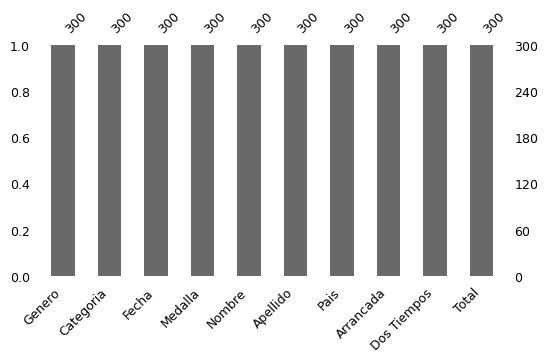

----------------------------------------------------------------------------------------------------
Missing-value pattern visualization:


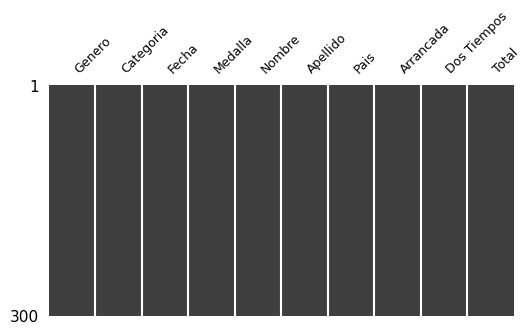

----------------------------------------------------------------------------------------------------


In [88]:
# Repeat basic and missing-value exploration on the final dataset
fpf.exploracion_basica(df_final)
fpf.exploracion_nulos(df_final)

### Dataset overview
The combined dataset covers five editions: 2019, 2021, 2022, 2023, and 2024. The 2021 edition is counted once. Its 60 supplied records are retained, including the source-version differences noted above.

In [89]:
# How many unique weight categories are there for each gender?
df_final.groupby('Genero')['Categoria'].nunique()

Genero
Femenino     10
Masculino    10
Name: Categoria, dtype: int64

Standard and open-ended weight classes are retained as separate categories. The number of observed categories may differ by gender and edition as competition classes change.

In [90]:
# What are the overall mean snatch, clean-and-jerk, and total results by gender?
df_resultados_por_genero = df_final.groupby('Genero').agg({
    'Arrancada':'mean',
    'Dos Tiempos':'mean',
    'Total':'mean',
}).round(2)
df_resultados_por_genero

,Arrancada,Dos Tiempos,Total
Genero,,,
Femenino,97.17,118.69,216.54
Masculino,159.31,192.35,351.67


### Average results by gender
The table summarizes the combined editions. Different weight-category ranges and the composition of medal-winning athletes limit interpretation of differences between the gender groups.

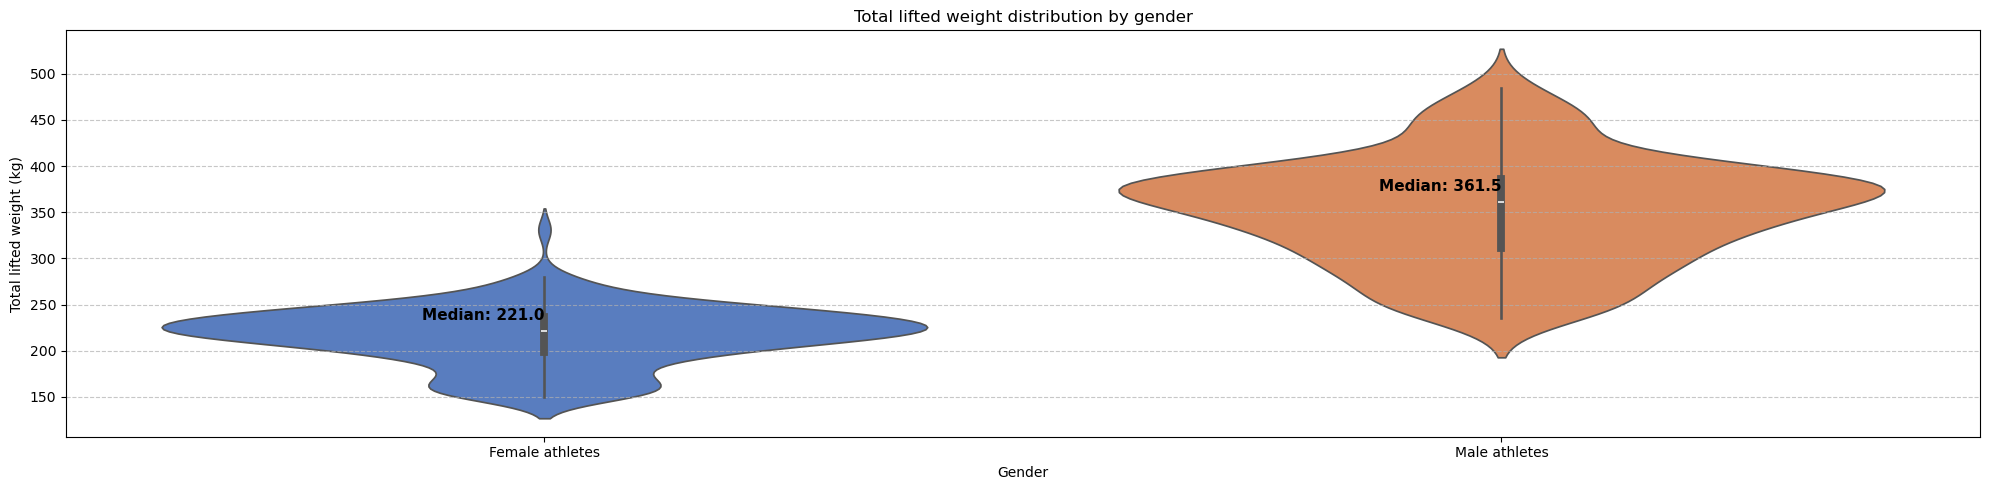

In [91]:
# How is total lifted weight distributed by gender?
fig, ax = plt.subplots(figsize = (20, 5))
sns.violinplot(
    data = df_final,
    x = 'Genero',
    y = 'Total',
    hue='Genero',
    palette='muted'
)

ax.set(
    title = 'Total lifted weight distribution by gender',
    xlabel = 'Gender',
    ylabel = 'Total lifted weight (kg)',
)

ax.grid(axis='y', linestyle='--', alpha=0.7)

medianas = df_final.groupby('Genero')['Total'].median()

for i, genero in enumerate(['Femenino', 'Masculino']):
    valor_mediana = medianas[genero]
    ax.text(
        x = i,                     
        y = valor_mediana + 12,    
        s = f"Median: {valor_mediana:.1f}",
        color = "black",           
        ha = "right",             
        fontweight = "bold",       
        fontsize = 11              
    )
ax.set_xticks(ax.get_xticks(), labels=['Female athletes', 'Male athletes'])
plt.tight_layout()


### Distribution of total lifted weight
The larger sample makes the peaks associated with weight categories more visible in both gender groups.

In [92]:
# What are the average snatch, clean-and-jerk, and total results by gender and category?
df_genero_categoria =df_final.groupby(['Genero','Categoria']).agg({
    'Arrancada':'mean',
    'Dos Tiempos':'mean',
    'Total':'mean',
})

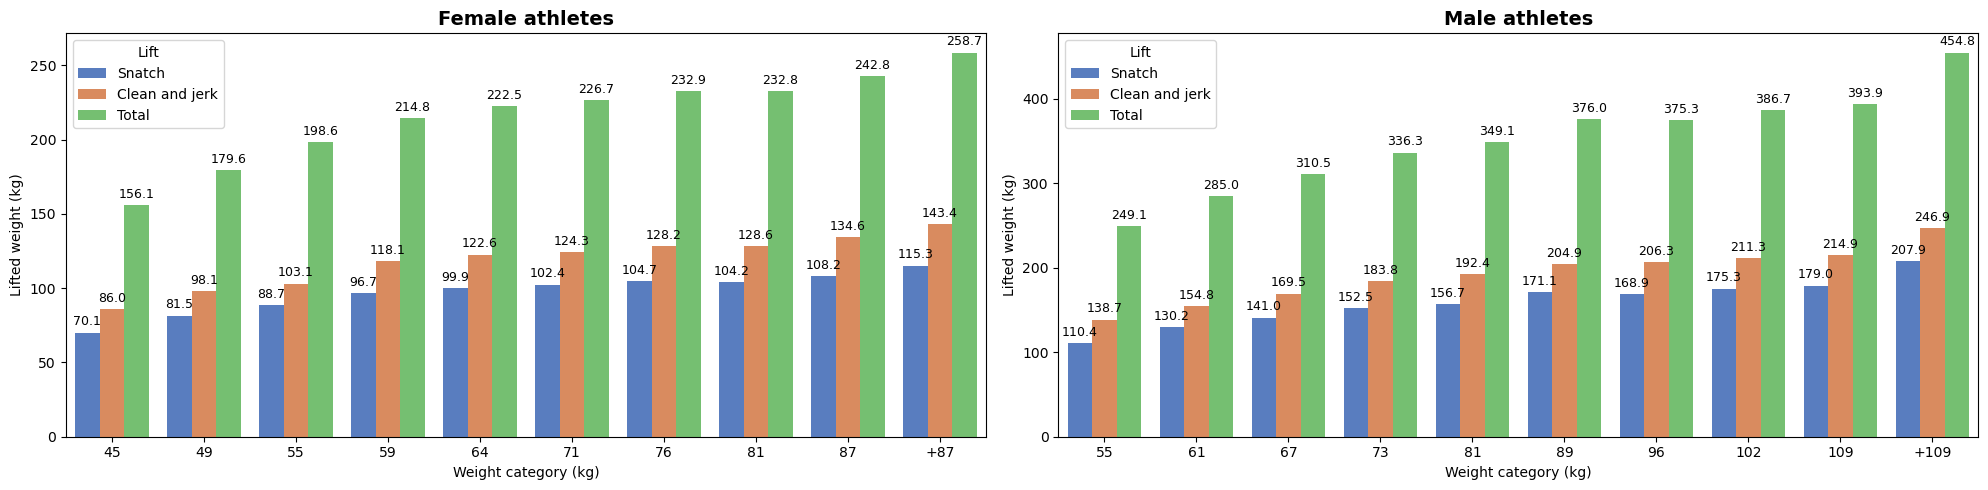

In [93]:
fig, ax = plt.subplots(1,2 , figsize=(20,5))

# Plot the results for female athletes
df_femenino = df_genero_categoria.query('Genero == "Femenino"').reset_index()
df_femenino['Categoria'] = df_femenino['Categoria'].cat.remove_unused_categories()

df_melted = pd.melt(
    df_femenino, 
    id_vars=['Categoria'], 
    value_vars=['Arrancada', 'Dos Tiempos', 'Total'],
    var_name='Lift', 
    value_name='Kilos'
)

sns.barplot(data = df_melted, x='Categoria', y='Kilos', hue='Lift', palette="muted", ax=ax[0])
ax[0].set_title('Female athletes', fontsize=14, fontweight='bold')

for container in ax[0].containers:
    ax[0].bar_label(container, fmt='%.1f', padding=3, fontsize=9)

# Plot the results for male athletes
df_masculino = df_genero_categoria.query('Genero == "Masculino"').reset_index()
df_masculino['Categoria'] = df_masculino['Categoria'].cat.remove_unused_categories()

df_melted = pd.melt(
    df_masculino, 
    id_vars=['Categoria'], 
    value_vars=['Arrancada', 'Dos Tiempos', 'Total'],
    var_name='Lift', 
    value_name='Kilos'
)

sns.barplot(data = df_melted, x='Categoria', y='Kilos', hue='Lift', palette="muted", ax=ax[1])
ax[1].set_title('Male athletes', fontsize=14, fontweight='bold')

for container in ax[1].containers:
    ax[1].bar_label(container, fmt='%.1f', padding=3, fontsize=9)
for panel in ax:
    panel.set_xlabel('Weight category (kg)')
    panel.set_ylabel('Lifted weight (kg)')
    handles, labels = panel.get_legend_handles_labels()
    panel.legend(handles, ['Snatch', 'Clean and jerk', 'Total'], title='Lift')
plt.tight_layout()


The category comparison retains the plus sign for open-ended classes and uses the combined dataset with each edition counted once.

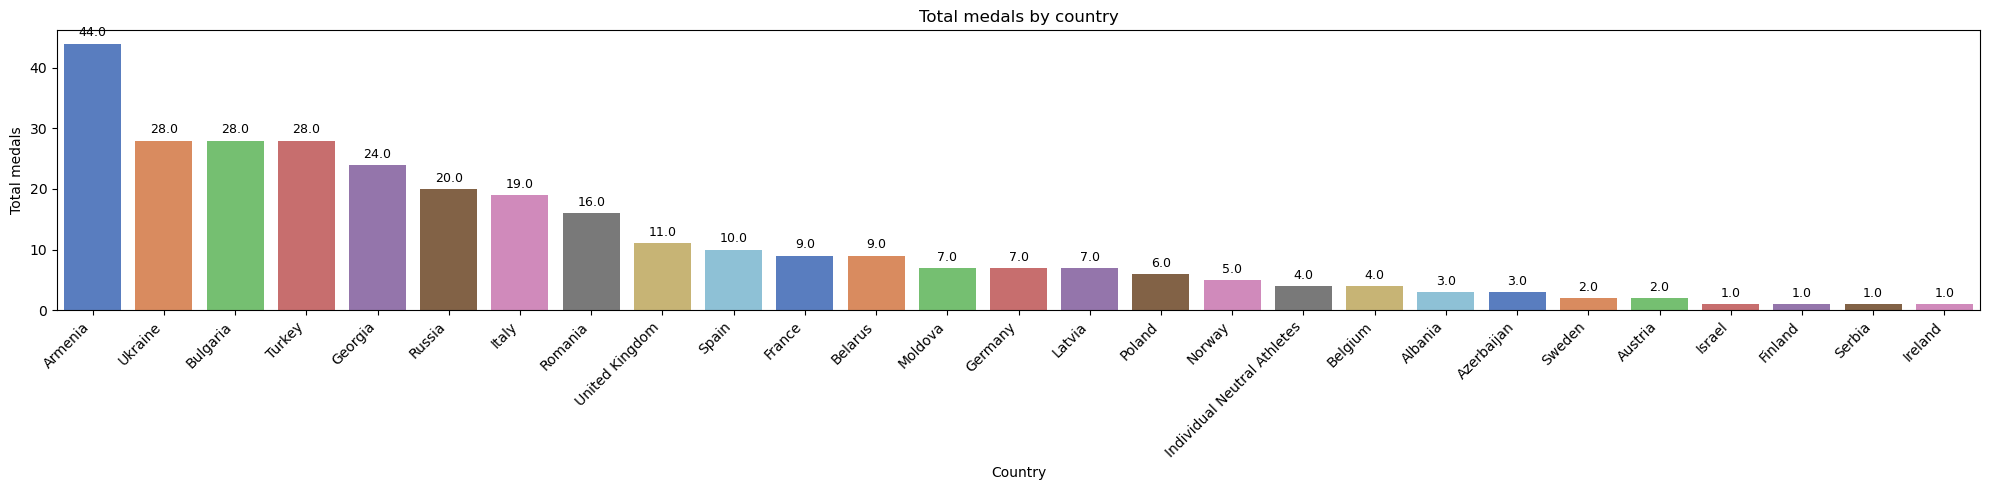

In [94]:
# How many total medals did each country win?
df_medallas_totales_pais = df_final.groupby('Pais')['Medalla'].count().sort_values(ascending=False).reset_index()

fig, ax = plt.subplots(figsize = (20, 5))
sns.barplot(
    data = df_medallas_totales_pais,
    x = 'Pais',
    y = 'Medalla',
    hue='Pais',
    palette="muted"
)

ax.set(
    title = 'Total medals by country',
    xlabel = 'Country',
    ylabel = 'Total medals',
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3, fontsize=9)
ax.set_xticks(ax.get_xticks(), labels=[country_labels.get(t.get_text(), t.get_text()) for t in ax.get_xticklabels()], rotation=45, ha='right')
plt.tight_layout()


### Country medal totals
The chart shows country medal counts across the five represented editions. The 2021 source is included once; the next table reports the medal breakdown.

## 8. Country comparisons in the combined results

### How many gold, silver, and bronze medals did each country win, regardless of gender?

In [95]:
df_medallas_pais = pd.crosstab(df_final['Pais'], df_final['Medalla'])
df_medallas_pais['Total'] = df_medallas_pais['Oro'] + df_medallas_pais['Plata'] + df_medallas_pais['Bronce']
df_medallas_pais = df_medallas_pais.sort_values(by='Total', ascending = False)
df_medallas_pais


Medalla,Oro,Plata,Bronce,Total
Pais,,,,
Armenia,14,13,17,44
Ucrania,12,10,6,28
Bulgaria,15,8,5,28
Turquía,8,9,11,28
Georgia,6,13,5,24
Rusia,4,9,7,20
Italia,8,8,3,19
Rumania,9,3,4,16
Reino Unido,5,2,4,11


The table distinguishes overall medal counts from gold-medal counts. These rankings describe the recorded competition outcomes, rather than participation or public interest.

### Which country has the most balanced medal success across female and male athletes?

In [96]:
df_diff_medalla = pd.crosstab(df_final['Pais'], df_final['Genero'], values=df_final['Medalla'], aggfunc='count').fillna(0)
df_diff_medalla['Diferencia'] = (df_diff_medalla['Femenino'] - df_diff_medalla['Masculino']).abs()
df_diff_medalla.sort_values(by='Diferencia')

Genero,Femenino,Masculino,Diferencia
Pais,,,
Irlanda,1.0,0.0,1.0
Alemania,4.0,3.0,1.0
Serbia,1.0,0.0,1.0
Moldavia,3.0,4.0,1.0
Azerbaiyán,1.0,2.0,1.0
Letonia,3.0,4.0,1.0
Israel,1.0,0.0,1.0
Finlandia,1.0,0.0,1.0
Suecia,2.0,0.0,2.0


The table orders countries by the absolute difference between female and male medal counts. Small differences can arise from very few medals and should be interpreted alongside the group counts.

### Which country has the smallest difference in mean total weight lifted by female and male athletes?

In [97]:
df_pais_genero = pd.crosstab(
    index=df_final['Pais'], 
    columns=df_final['Genero'], 
    values=df_final['Total'], 
    aggfunc='mean'
).fillna(0)

In [98]:
# Keep countries represented in both gender groups
df_pais_genero = df_pais_genero[(df_pais_genero['Femenino'] != 0) & (df_pais_genero['Masculino'] != 0)]

In [99]:
# Calculate the absolute difference
df_pais_genero['Diferencia'] = (df_pais_genero['Masculino'] - df_pais_genero['Femenino']).abs()
df_pais_genero = df_pais_genero.rename_axis(columns = '')
solucion = df_pais_genero['Diferencia'].idxmin().upper()

In [100]:
# Report the result using English display labels.
print(f'The country with the smallest difference in mean total lifted weight between female and male medallists is {country_labels.get(solucion.title(), solucion.title())}.')

The country with the smallest difference in mean total lifted weight between female and male medallists is Romania.


## 9. Conclusions and limitations

The workflow turns semi-structured medal tables into athlete-level records, then compares medal counts and lifting results using the same descriptive questions in both stages.

- The supplied files represent 2019 and the postponed 2021 championship. The combined dataset adds 2022–2024 and counts the 2021 edition once.
- The supplied historical 2021 source version is retained. Three women’s 59 kg medal records differ from the current source page; the results should not be described as the latest official medal allocation.
- The dataset contains medallists, rather than all competitors or the general population. Medal counts do not establish demand for a training centre.
- Total-weight comparisons across genders involve different weight-category ranges and athlete composition.
- Open-ended weight classes remain separate from standard classes.
- Scraping depends on external page availability and table structure.

## Project background

Adapted from the original Nuclio Digital School data-analysis project. The original CSV files, extraction functions, and two-stage workflow are preserved. [Original case in English](docs/weightlifting_project_brief.md) · [Source checks](docs/source_validation.md).
